# Project Group - 

Members: Ivo Weidema

Student numbers: 

# Research Objective

*Requires data modeling and quantitative research in Transport, Infrastructure & Logistics*

# Contribution Statement

*Be specific. Some of the tasks can be coding (expect everyone to do this), background research, conceptualisation, visualisation, data analysis, data modelling*

**Author 1**:

**Author 2**:

**Author 3**:

# Data Used

crowd sensoren van Sail 2025

In [11]:
import pandas as pd
import calendar
import matplotlib.pyplot as plt


In [12]:
# 1. Exacte bestandsnamen
flow_file = "sensordata_SAIL2025.csv"
location_file = "sensor-location.xlsx - Sheet1.csv"

# 2. Inladen met pandas
df_flow = pd.read_csv(flow_file)
df_flow["timestamp"] = pd.to_datetime(df_flow["timestamp"])

df_location = pd.read_csv(location_file)

# 3. De 5 geselecteerde sensoren
selected_sensors = [
    "GASA-03",  # Oosterdoksbrug (primaire brede walkway)
    "GASA-04",  # CS ri. Oosterdokskade (hoofduitstroom station)
    "GASA-02-01",  # Brug Oostertoegang 1 (corridor knelpunt)
    "GASA-01-B",  # IJBoulevard B (boulevard aan het water)
    "GVCV-03",  # CS ri. Buiksloterweg West (veerpont)
]

# 4. Filteren op locatiedata
# (vangt zowel 'Objectnummer' als 'Objectummer' op)
obj_col = (
    "Objectnummer" if "Objectnummer" in df_location.columns else "Objectummer"
)
eff_col = [c for c in df_location.columns if "Effectieve" in c][0]

df_location_filtered = df_location[
    df_location[obj_col].isin(selected_sensors)
].copy()

# 5. Filteren op flow data (tijdskolommen + de twee richtingen per sensor)
meta_cols = ["timestamp", "hour", "minute", "day", "month", "weekday", "is_weekend"]
sensor_cols = [
    col
    for col in df_flow.columns
    if any(col.startswith(s + "_") for s in selected_sensors)
]

df_flow_filtered = df_flow[meta_cols + sensor_cols].copy()

# 6. Totale loopstroom per sensor berekenen (som van beide looprichtingen)
for sensor in selected_sensors:
  dirs = [col for col in sensor_cols if col.startswith(sensor + "_")]
  df_flow_filtered[f"{sensor}_total"] = df_flow_filtered[dirs].sum(axis=1)

# 7. Overzicht printen
print("=== Geselecteerde Sensoren ===")
print(df_location_filtered[[obj_col, "Locatienaam", eff_col, "Lat/Long"]])

print("\n=== Eerste rijen van de totale loopstromen ===")
preview_cols = ["timestamp"] + [f"{s}_total" for s in selected_sensors]
print(df_flow_filtered[preview_cols].head())

=== Geselecteerde Sensoren ===
   Objectnummer                    Locatienaam Effectieve breedte  \
14      GVCV-03  CS - ri. Buiksloterweg (West)                3,1   
28    GASA-01-B                   IJBoulevardB                  6   
30   GASA-02-01             BrugOostertoegang1                  6   
32      GASA-03                 Oosterdoksbrug                  8   
33      GASA-04             CSriOosterdokskade                  7   

               Lat/Long  
14   52.380566,4.899360  
28  52.380340, 4.899920  
30  52.378640, 4.904720  
32  52.377620, 4.911010  
33  52.377020, 4.903520  

=== Eerste rijen van de totale loopstromen ===
                  timestamp  GASA-03_total  GASA-04_total  GASA-02-01_total  \
0 2025-08-20 00:00:00+02:00              0              0                 0   
1 2025-08-20 00:03:00+02:00              0              0                 0   
2 2025-08-20 00:06:00+02:00              0              0                 0   
3 2025-08-20 00:09:00+02:00       

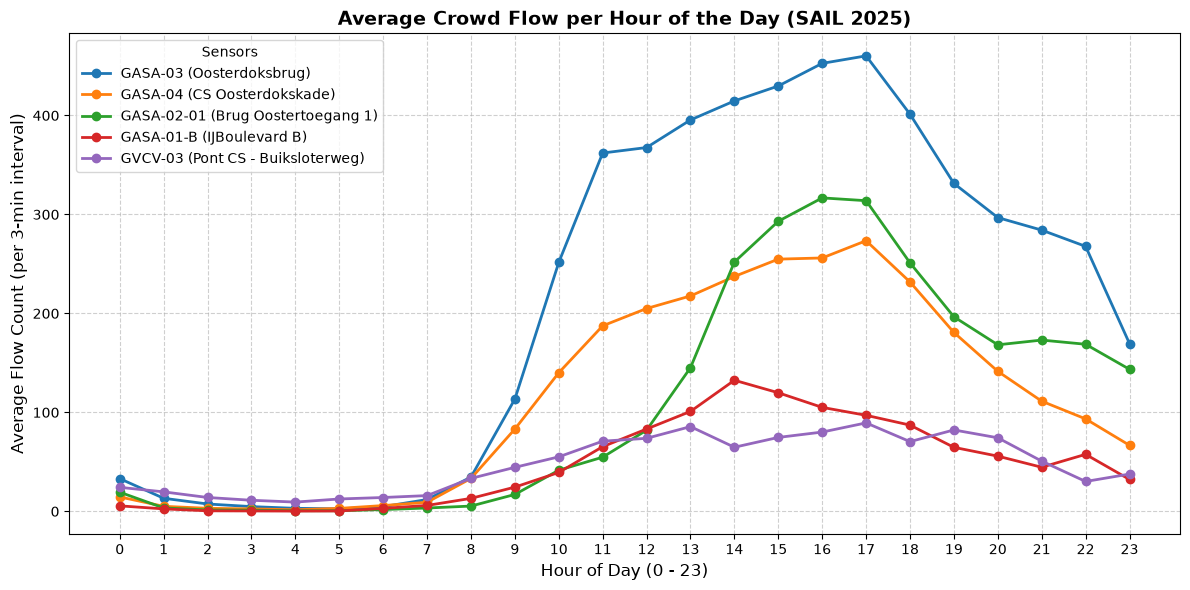

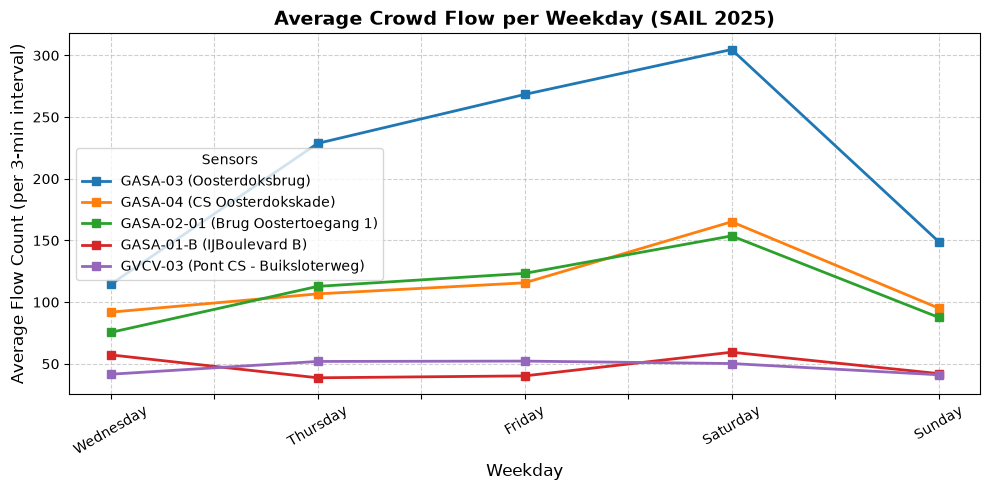

In [13]:
# 1. Flow dataset inladen
df_flow = pd.read_csv("sensordata_SAIL2025.csv")
df_flow["timestamp"] = pd.to_datetime(df_flow["timestamp"])

# 2. De 5 sensoren selecteren en totale stromen berekenen
date_time = ["timestamp", "hour", "minute", "day", "weekday", "is_weekend"]
base_sensors = ["GASA-03", "GASA-04", "GASA-02-01", "GASA-01-B", "GVCV-03"]

df_five_sensors = df_flow[date_time].copy()
for s in base_sensors:
  dirs = [col for col in df_flow.columns if col.startswith(s + "_")]
  df_five_sensors[f"{s}_total"] = df_flow[dirs].sum(axis=1)

# 3. Kolommen en labels voor de visualisaties
sensors_to_plot = [f"{s}_total" for s in base_sensors]
sensor_labels = {
    "GASA-03_total": "GASA-03 (Oosterdoksbrug)",
    "GASA-04_total": "GASA-04 (CS Oosterdokskade)",
    "GASA-02-01_total": "GASA-02-01 (Brug Oostertoegang 1)",
    "GASA-01-B_total": "GASA-01-B (IJBoulevard B)",
    "GVCV-03_total": "GVCV-03 (Pont CS - Buiksloterweg)",
}

# --- Plot 1: Gemiddelde loopstroom per uur van de dag ---
plt.figure(figsize=(12, 6))
for sensor in sensors_to_plot:
  df_five_sensors.groupby("hour")[sensor].mean().plot(
      label=sensor_labels.get(sensor, sensor), marker="o", linewidth=2
  )

plt.title(
    "Average Crowd Flow per Hour of the Day (SAIL 2025)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Hour of Day (0 - 23)", fontsize=12)
plt.ylabel("Average Flow Count (per 3-min interval)", fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title="Sensors", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# --- Plot 2: Gemiddelde loopstroom per weekdag ---
weekday_names = [calendar.day_name[i] for i in range(7)]

plt.figure(figsize=(10, 5))
for sensor in sensors_to_plot:
  weekday_means = df_five_sensors.groupby("weekday")[sensor].mean()
  weekday_means.index = [weekday_names[i] for i in weekday_means.index]
  weekday_means.plot(
      label=sensor_labels.get(sensor, sensor), marker="s", linewidth=2
  )

plt.title(
    "Average Crowd Flow per Weekday (SAIL 2025)", fontsize=14, fontweight="bold"
)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Average Flow Count (per 3-min interval)", fontsize=12)
plt.legend(title="Sensors", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Data Pipeline